# Validation of the padding procedure and selection of the k-mer length.

In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
from scripts.functions.colors import shm_colors
color_violet = shm_colors['color_violet']
color_gray = shm_colors['color_gray']

import seaborn as sn
from scripts.functions import mutation_matrix as mm


muts = pd.read_csv('data/Spisak_mutabilities_context.tsv', sep ="\t")

## a-b: Comparison of codon-level log stationary frequencies and diffusion axis 1 values calculated from mutation matrices of consecutive $k$-mer lengths.

Generating transition matrix: 100%|██████████| 1048576/1048576 [27:39<00:00, 631.73it/s]


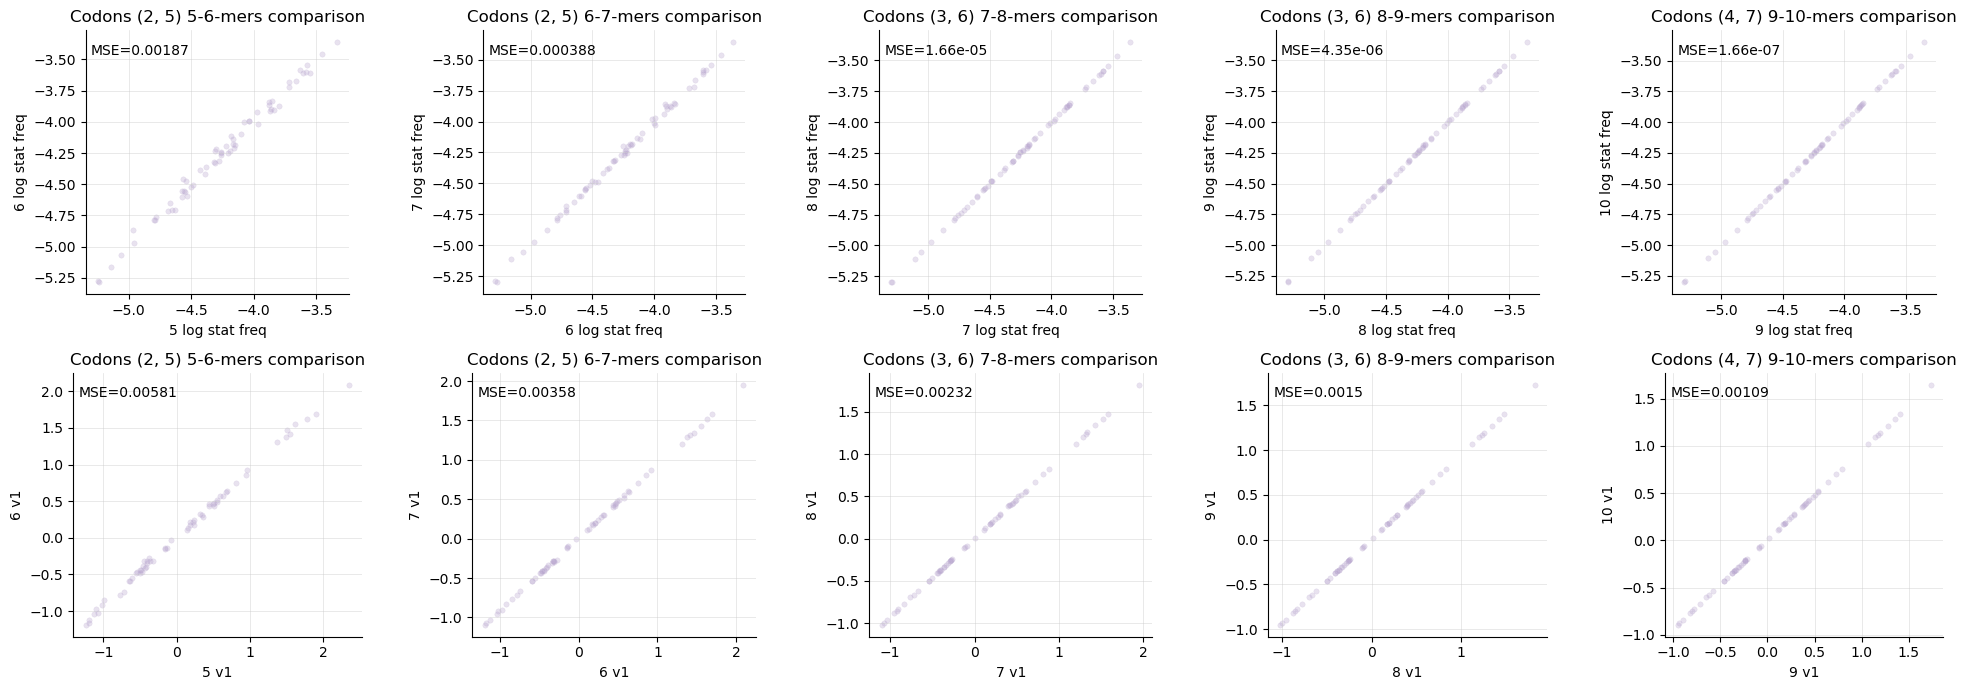

In [2]:
kmers = [5, 6, 7, 8, 9]
# kmers = [6, 7, 8, 9, 10]
l_context = 2
codons = mm.generate_all_sequences(3)

l_seq1 = kmers[0]
sequences1 = mm.generate_all_sequences(l_seq1)
mutation_matrix_sp1 = mm.compute_mutmatrix(sequences1, muts, l_seq1, l_context)
right_eigvals_real1, stat_freq_norm1, v1_1, v2_1 = mm.k_eigenvectors_phased(10, mutation_matrix_sp1, sequences1)

## codons for the first k
cp1 = l_seq1 // 2 - 1
cp2 = cp1 + 3
idx = mm.kmer_to_codon(codons, l_seq1, p1=cp1, p2=cp2)  # <-- bugfix: use l_seq1, not k
cstat_freq_norm1 = mm.sum_codons(codons, sequences1, stat_freq_norm1.real, 'sum', cp1, cp2)
cv1_1 = mm.sum_codons(codons, sequences1, v1_1.real, 'average', cp1, cp2)

## storage for RMSD per transition k -> k+1
mse_stat = []
mse_v1 = []
eps = 1e-12  # for safe log

fig, axes = plt.subplots(2, len(kmers), figsize=(len(kmers)*4, 7))

for i, k in enumerate(kmers):
    l_seq2 = k + 1
    sequences2 = mm.generate_all_sequences(l_seq2)
    mutation_matrix_sp2 = mm.compute_mutmatrix(sequences2, muts, l_seq2, l_context)
    right_eigvals_real2, stat_freq_norm2, v1_2, v2_2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp2, sequences2)

    ## codons
    cp1 = l_seq2 // 2 - 1
    cp2 = cp1 + 3
    idx = mm.kmer_to_codon(codons, l_seq2, p1=cp1, p2=cp2)  # <-- bugfix: use l_seq2, not k
    cstat_freq_norm2 = mm.sum_codons(codons, sequences2, stat_freq_norm2.real, 'sum', cp1, cp2)
    cv1_2 = mm.sum_codons(codons, sequences2, v1_2.real, 'average', cp1, cp2)

    ## RMSD calculations
    ### match the scatter's log-space comparison for stat freqs
    x1 = np.log(np.clip(cstat_freq_norm1, eps, None))
    x2 = np.log(np.clip(cstat_freq_norm2, eps, None))
    mse_stat_k = np.mean((x2 - x1) ** 2)
    mse_v1_k = np.mean((cv1_2 - cv1_1) ** 2)
    mse_stat.append(mse_stat_k)
    mse_v1.append(mse_v1_k)

    ## v1-v1+1 scatterplots
    sn.scatterplot(
        x=np.log(np.clip(cstat_freq_norm1, eps, None)),
        y=np.log(np.clip(cstat_freq_norm2, eps, None)),
        s=15, color=color_violet, alpha=0.3, edgecolor=color_violet, ax=axes[0, i])

    axes[0, i].set_title(f'Codons ({cp1}, {cp2}) {k}-{k+1}-mers comparison')
    axes[0, i].set_xlabel(f'{k} log stat freq')
    axes[0, i].set_ylabel(f'{k+1} log stat freq')
    ## annotate MSE on the panel
    axes[0, i].text(0.02, 0.95, f'MSE={mse_stat_k:.3g}', transform=axes[0, i].transAxes,
                    ha='left', va='top')
    axes[0, i].set_aspect('equal', adjustable='box')
    axes[0, i].grid(True, alpha=0.6, color = '#CCCCCC')

    sn.scatterplot(
        x=cv1_1, y=cv1_2,
        s=15, color=color_violet, alpha=0.3, edgecolor=color_violet, ax=axes[1, i])

    axes[1, i].set_title(f'Codons ({cp1}, {cp2}) {k}-{k+1}-mers comparison')
    axes[1, i].set_xlabel(f'{k} v1')
    axes[1, i].set_ylabel(f'{k+1} v1')
    ## annotate MSE on the panel
    axes[1, i].text(0.02, 0.95, f'MSE={mse_v1_k:.3g}', transform=axes[1, i].transAxes,
                    ha='left', va='top')
    axes[1, i].set_aspect('equal', adjustable='box')
    axes[1, i].grid(True, alpha=0.6, color = '#CCCCCC')

    ## next iteration
    sequences1 = sequences2
    cstat_freq_norm1 = cstat_freq_norm2
    cv1_1 = cv1_2

plt.tight_layout()
sn.despine()

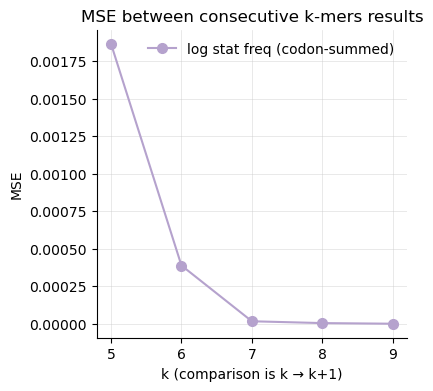

In [3]:
fig2, ax2 = plt.subplots(1, 1, figsize=(4, 4))
ax2.plot(kmers, mse_stat, marker='o', label='log stat freq (codon-summed)', markersize = 7, color = color_violet)
ax2.set_xlabel('k (comparison is k → k+1)')
ax2.set_ylabel('MSE')
ax2.set_xticks(kmers)
ax2.grid(True, alpha=0.6, color = '#CCCCCC')
ax2.set_title('MSE between consecutive k-mers results')
ax2.legend(frameon=False)
sn.despine()

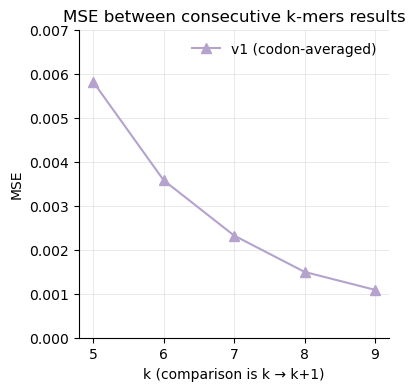

In [4]:
fig2, ax2 = plt.subplots(1, 1, figsize=(4, 4))
ax2.plot(kmers, mse_v1, marker='^', label='v1 (codon-averaged)', markersize = 7, color = color_violet)
ax2.set_xlabel('k (comparison is k → k+1)')
ax2.set_ylabel('MSE')
ax2.set_xticks(kmers)
ax2.set_ylim(0, 0.007)
ax2.grid(True, alpha=0.6, color = '#CCCCCC')
ax2.set_title('MSE between consecutive k-mers results')
ax2.legend(frameon=False)
sn.despine()

## c: Comparison of log stationary frequencies estimated from the padded k-mer mutation matrices and those obtained from mutation simulations on full-length BCR sequences.

Generating transition matrix: 100%|██████████| 1048576/1048576 [27:50<00:00, 627.81it/s]


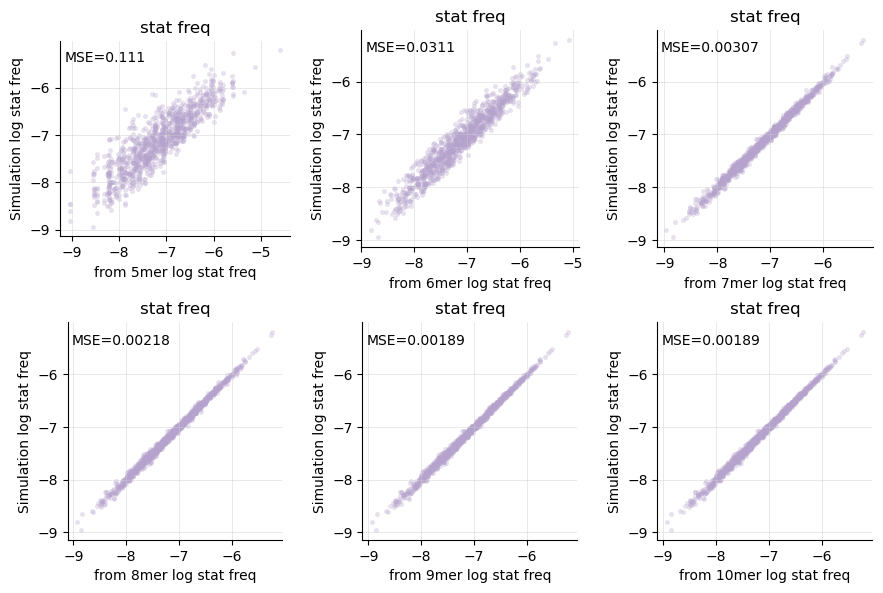

In [5]:
k_to_test = [5, 6, 7, 8, 9, 10]
mse_stat = []

jobid_p = '20260916'
nseq_p = 2000
stop_p = 300
resulting_table = pd.read_csv(f'results/transition-matrix_calculation/id{jobid_p}-nseq{nseq_p}-stop{stop_p}-burnt2_mutability.csv')

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
axes = axes.ravel()

for i, l_seq in enumerate(k_to_test):

    l_context = 2
    sequences_eig = mm.generate_all_sequences(l_seq)
    mutation_matrix_sp = mm.compute_mutmatrix(sequences_eig, muts, l_seq, l_context)

    cp1 = l_seq//2 - 2
    cp2 = cp1 + 5

    right_eigvals_real, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp, sequences_eig)

    nmers = mm.generate_all_sequences(5)
    n5stat_freq_norm1 = mm.sum_nmers(nmers, sequences_eig, stat_freq_norm.real, "sum", cp1, cp2)

    sn.scatterplot(
        x=np.log(np.clip(n5stat_freq_norm1, 1e-12, None)),
        y=np.log(np.clip(resulting_table['stat freq'], 1e-12, None)),
        ax=axes[i],
        s=10,
        color=color_violet,
        alpha=0.3,
        edgecolor=color_violet)

    axes[i].set_xlabel(f'from {l_seq}mer log stat freq')
    axes[i].set_ylabel('Simulation log stat freq')
    axes[i].set_title('stat freq')
    axes[i].set_aspect('equal')
    axes[i].grid(True, alpha=0.6, color='#CCCCCC')

    mse_stat_k = np.mean(
        (np.log(np.clip(n5stat_freq_norm1, 1e-12, None)) - np.log(np.clip(resulting_table['stat freq'], 1e-12, None))) ** 2)

    mse_stat.append(mse_stat_k)

    ## annotate MSE on the panel
    axes[i].text(
        0.02, 0.95,
        f'MSE={mse_stat_k:.3g}',
        transform=axes[i].transAxes,
        ha='left',
        va='top')

plt.tight_layout()
sn.despine()

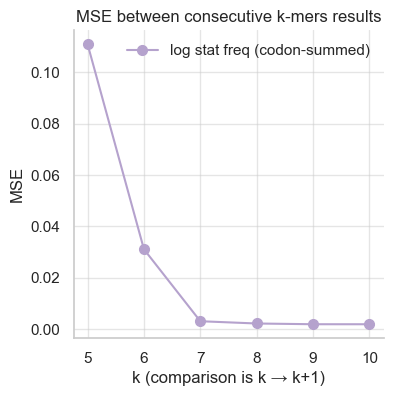

In [6]:
## summary plot of MSE vs k
sn.set_theme(style="whitegrid")

fig2, ax2 = plt.subplots(1, 1, figsize=(4, 4))
ax2.plot(k_to_test, mse_stat, marker='o', label='log stat freq (codon-summed)', markersize = 7, color = color_violet)
#ax2.plot(kmers, rmsd_v1, marker='^', label='v1 (codon-averaged)', markersize = 7, color = color_violet)
ax2.set_xlabel('k (comparison is k → k+1)')
ax2.set_ylabel('MSE')
ax2.set_xticks(k_to_test)
ax2.set_title('MSE between consecutive k-mers results')
ax2.legend(frameon=False)
sn.despine()